# Guardian Deity – Women Safety Audio Classification
Classifies audio clips into three classes: **Women**, **Child** and **Normal**, using 16 audio features and five models (Random Forest, Decision Tree, Logistic Regression, Gaussian Naive Bayes, TCN with Attention).

Dataset: *Audio Signal Dataset for Danger Detection of Women and Children* (download the zip yourself and keep it next to this notebook).

## Step 1: Install libraries

In [2]:
%pip install librosa matplotlib numpy soundfile pandas scikit-learn seaborn openpyxl tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2: Set seeds
A seed makes the "random" parts give the same result every time you run the notebook.

In [3]:
import numpy as np
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

## Step 3: Unzip and find the dataset

In [4]:
from pathlib import Path
import zipfile

# The downloaded zip must be in the same folder as this notebook
zip_path = next(Path(".").glob("Audio Signal Dataset*.zip"))  # finds the zip in the same folder as this notebook

# Extract into a folder named Audio_Dataset
extract_dir = zip_path.parent / "Audio_Dataset"

if zip_path.exists():
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Dataset extracted successfully!")
    print("Location:", extract_dir)
else:
    print("ZIP file not found. Check the file path.")

Dataset extracted successfully!
Location: Audio_Dataset


In [5]:
from pathlib import Path

base = Path("Audio_Dataset")  # created by the cell above

# Search inside Audio_Dataset for a folder named "train"
train_dirs = [p for p in base.rglob("train") if p.is_dir()]
print("Found:", train_dirs)

root_dir = str(train_dirs[0])
categories = ['Women', 'Child', 'Normal']

# All three should print True
for c in categories:
    print(c, Path(root_dir, c).exists())

Found: [WindowsPath('Audio_Dataset/Audio Signal Dataset for Danger Detection of Women\xa0and\xa0Children/train')]
Women True
Child True
Normal True


The dataset already comes with a separate `test` folder (made for testing). We train on `train` and test on `test`, so the model is checked on clips it has never seen.

In [6]:
# The dataset already has a separate "test" folder next to "train"
test_dir = str(Path(root_dir).parent / "test")
for c in categories:
    print("test /", c, Path(test_dir, c).exists())   # all three should print True

test / Women True
test / Child True
test / Normal True


## Step 4: Look at one audio clip

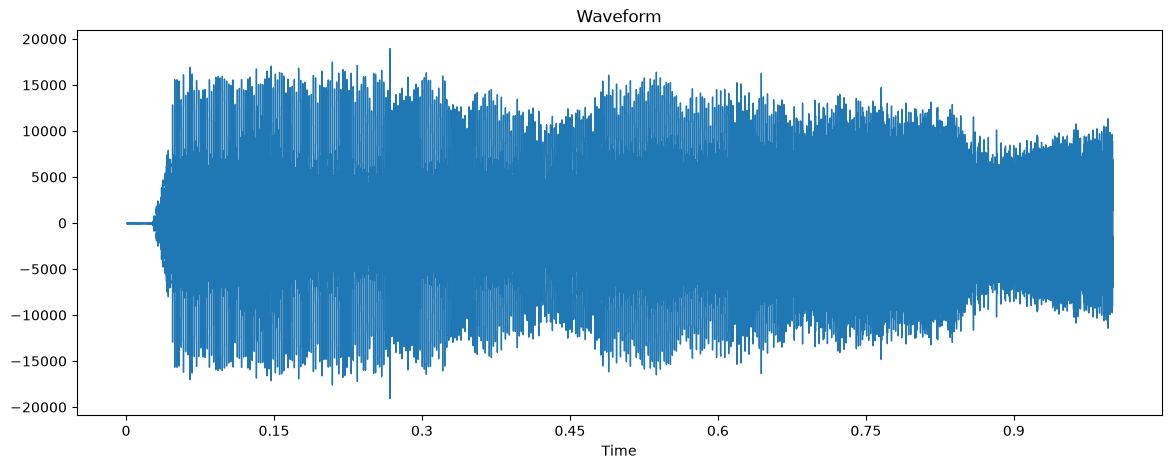

Audio loaded successfully. Sample rate: 22050 Hz


In [7]:
import os
import librosa
import librosa.display
import matplotlib.pyplot as plt

sample_folder = os.path.join(root_dir, "Child")
sample_file = [f for f in os.listdir(sample_folder) if f.endswith(".wav")][0]
audio_path = os.path.join(sample_folder, sample_file)

y, sr = librosa.load(audio_path)

plt.figure(figsize=(14, 5))
librosa.display.waveshow(y, sr=sr)
plt.title("Waveform")
plt.show()

print(f"Audio loaded successfully. Sample rate: {sr} Hz")


## Step 5: Extract audio features
For each clip we calculate 16 numbers: ZCR, RMS, Spectral Centroid and 13 MFCCs (averaged over the clip). We do this for both the `train` and the `test` folder.

In [8]:
import os
import librosa
import numpy as np
import pandas as pd

# Feature extraction function
def extract_features(file_path):
    y, sr = librosa.load(file_path, sr=None)

    features = {
        "zcr": np.mean(librosa.feature.zero_crossing_rate(y)),
        "rms": np.mean(librosa.feature.rms(y=y)),
        "spectral_centroid": np.mean(librosa.feature.spectral_centroid(y=y, sr=sr)),
    }

    # MFCCs: we take the mean of the first 13 coefficients
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    for i in range(13):
        features[f'mfcc_{i+1}'] = np.mean(mfccs[i])

    return features

def build_feature_table(folder_root):
    rows = []
    for label in categories:
        folder_path = os.path.join(folder_root, label)
        for file in os.listdir(folder_path):
            if file.endswith('.wav'):
                file_path = os.path.join(folder_path, file)
                try:
                    features = extract_features(file_path)
                    features['label'] = label
                    rows.append(features)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    return pd.DataFrame(rows)

# Train features and test features (this step takes a while)
df_train = build_feature_table(root_dir)
df_test = build_feature_table(test_dir)

# Save so you can reuse them later (optional)
df_train.to_excel(os.path.join(root_dir, 'audio_features_train.xlsx'), index=False)
df_test.to_excel(os.path.join(test_dir, 'audio_features_test.xlsx'), index=False)

print("Feature extraction complete.")
print("Train clips:", len(df_train), "| Test clips:", len(df_test))

Error processing Audio_Dataset\Audio Signal Dataset for Danger Detection of Women and Children\test\Normal\1112_21_right.wav: Error opening 'Audio_Dataset\\Audio Signal Dataset for Danger Detection of Women\xa0and\xa0Children\\test\\Normal\\1112_21_right.wav': Format not recognised.
Error processing Audio_Dataset\Audio Signal Dataset for Danger Detection of Women and Children\test\Normal\1112_22.wav: Error opening 'Audio_Dataset\\Audio Signal Dataset for Danger Detection of Women\xa0and\xa0Children\\test\\Normal\\1112_22.wav': Format not recognised.
Error processing Audio_Dataset\Audio Signal Dataset for Danger Detection of Women and Children\test\Normal\1113_0_patch.wav: Error opening 'Audio_Dataset\\Audio Signal Dataset for Danger Detection of Women\xa0and\xa0Children\\test\\Normal\\1113_0_patch.wav': Format not recognised.
Error processing Audio_Dataset\Audio Signal Dataset for Danger Detection of Women and Children\test\Normal\1113_13_left.wav: Error opening 'Audio_Dataset\\Audio S

## Step 6: Training data and testing data
Training data comes from the `train` folder and testing data from the `test` folder, so no random split is needed.

In [9]:
# Input features = every column except the label
inputs = [col for col in df_train.columns if col != 'label']

X_train = df_train[inputs]
y_train = df_train['label']
X_test = df_test[inputs]      # clips from the separate test folder
y_test = df_test['label']

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (13562, 16)
X_test shape: (5777, 16)
y_train shape: (13562,)
y_test shape: (5777,)


## Step 7: Scale the features
The features have very different sizes, so we bring them to a similar scale. The scaler learns only from the training data, so the test data stays unseen.

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Step 8: Random Forest

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest Classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model on the training data
model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


Cross-validation tests the model on 5 different parts of the training data to show that the score is stable.

In [12]:
from sklearn.model_selection import cross_val_score

# Cross-validation uses the training data only; the test folder stays untouched
scores = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42),
                         X_train, y_train, cv=5, scoring="accuracy")
print("Fold scores:", scores.round(4))
print(f"Mean: {scores.mean():.4f}  +/- {scores.std():.4f}")

Fold scores: [0.7272 0.9337 0.9111 0.9318 0.9012]
Mean: 0.8810  +/- 0.0779


## Step 9: Logistic Regression and Naive Bayes

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train the Logistic Regression model
log_reg_model = LogisticRegression(max_iter=1000, random_state=42) # Increased max_iter for convergence
log_reg_model.fit(X_train_scaled, y_train)

# Predict and evaluate Logistic Regression
y_pred_lr = log_reg_model.predict(X_test_scaled)
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"Accuracy of the Logistic Regression model: {accuracy_lr:.4f}")
print("\nClassification Report (Logistic Regression):\n", classification_report(y_test, y_pred_lr))

print("-" * 30) # Separator for clarity

# Initialize and train the Gaussian Naive Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Predict and evaluate Naive Bayes
y_pred_nb = nb_model.predict(X_test)
accuracy_nb = accuracy_score(y_test, y_pred_nb)
print(f"Accuracy of the Gaussian Naive Bayes model: {accuracy_nb:.4f}")
print("\nClassification Report (Gaussian Naive Bayes):\n", classification_report(y_test, y_pred_nb))

Accuracy of the Logistic Regression model: 0.7738

Classification Report (Logistic Regression):
               precision    recall  f1-score   support

       Child       0.64      0.96      0.77      1946
      Normal       0.98      0.91      0.94      1902
       Women       0.80      0.45      0.58      1929

    accuracy                           0.77      5777
   macro avg       0.81      0.77      0.76      5777
weighted avg       0.81      0.77      0.76      5777

------------------------------
Accuracy of the Gaussian Naive Bayes model: 0.7497

Classification Report (Gaussian Naive Bayes):
               precision    recall  f1-score   support

       Child       0.59      0.95      0.73      1946
      Normal       1.00      0.94      0.97      1902
       Women       0.80      0.36      0.49      1929

    accuracy                           0.75      5777
   macro avg       0.80      0.75      0.73      5777
weighted avg       0.79      0.75      0.73      5777



## Step 10: Decision Tree

In [14]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree Classifier
decision_tree_model = DecisionTreeClassifier(random_state=42)

# Train the model on the training data
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


## Step 11: Confusion matrices

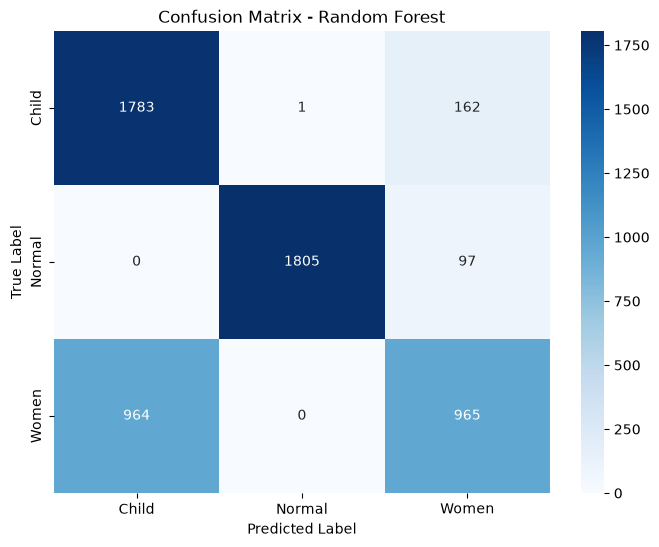

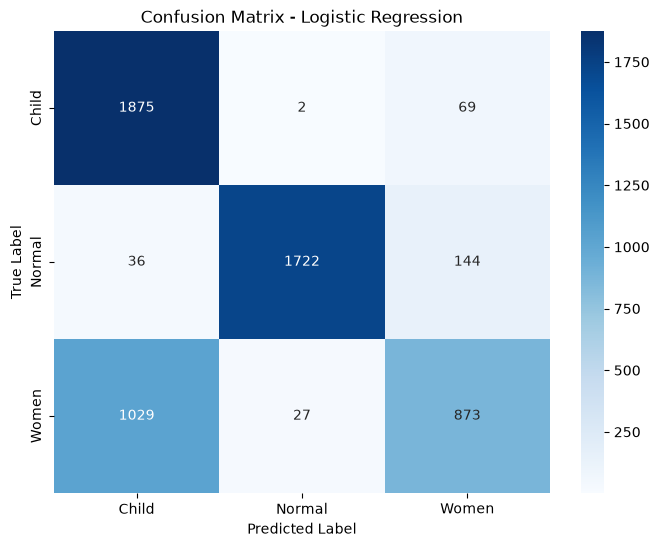

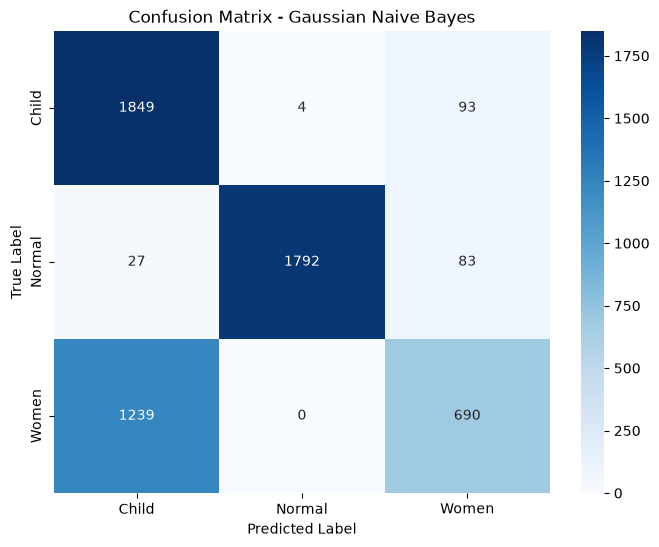

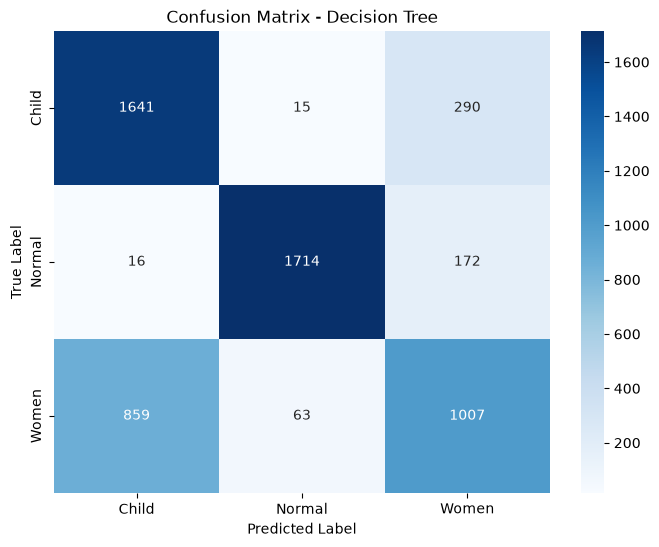

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrix for Random Forest
y_pred = model.predict(X_test)
cm_rf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Generate confusion matrix for Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', xticklabels=log_reg_model.classes_, yticklabels=log_reg_model.classes_)
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Generate confusion matrix for Gaussian Naive Bayes
cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', xticklabels=nb_model.classes_, yticklabels=nb_model.classes_)
plt.title('Confusion Matrix - Gaussian Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Generate confusion matrix for Decision Tree
cm_dt = confusion_matrix(y_test, decision_tree_model.predict(X_test))

plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', xticklabels=decision_tree_model.classes_, yticklabels=decision_tree_model.classes_)
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


## Step 12: TCN with Attention
Note: the 16 features are clip-level averages, so the TCN treats them as a short sequence of feature values, not as audio over time.

In [16]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, Reshape, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Conv1D, Activation, Add, Multiply
from tensorflow.keras import backend as K
from tensorflow.keras.initializers import RandomNormal
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.layers import Layer

# Define the TCN block
def tcn_block(input_layer, filters, kernel_size, dilation_rate, dropout_rate, activation='relu'):
    # Save the input for the residual connection
    residual = input_layer

    # First convolutional layer
    conv1 = Conv1D(filters, kernel_size, dilation_rate=dilation_rate, padding='causal',
                   kernel_initializer=RandomNormal(mean=0.0, stddev=0.02))(input_layer)
    conv1 = Activation(activation)(conv1)
    conv1 = Dropout(dropout_rate)(conv1)

    # Second convolutional layer
    conv2 = Conv1D(filters, kernel_size, dilation_rate=dilation_rate, padding='causal',
                   kernel_initializer=RandomNormal(mean=0.0, stddev=0.02))(conv1)
    conv2 = Activation(activation)(conv2)
    conv2 = Dropout(dropout_rate)(conv2)

    # Residual connection
    # If the number of filters changed, we need a 1x1 convolution for the residual
    if K.int_shape(residual)[-1] != filters:
        residual = Conv1D(filters, 1, padding='same')(residual)

    # Add the residual to the output of the block
    output_layer = Add()([residual, conv2])
    output_layer = Activation(activation)(output_layer) # Activation after adding residual

    return output_layer

# Custom Attention Layer
class Attention(Layer):
    def __init__(self, **kwargs):
        super(Attention, self).__init__(**kwargs)

    def build(self, input_shape):
        # input_shape is (None, sequence_length, features)
        self.W = self.add_weight(name='attention_w', shape=(input_shape[-1], input_shape[-1]),
                                 initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(name='attention_b', shape=(input_shape[-1],),
                                 initializer='zeros', trainable=True)
        # u should have the same dimension as features, but will be used as a column vector
        self.u = self.add_weight(name='attention_u', shape=(input_shape[-1], 1),
                                 initializer='glorot_uniform', trainable=True)
        super(Attention, self).build(input_shape)

    def call(self, x):
        # x shape is (None, sequence_length, features)
        # uit shape will be (None, sequence_length, features)
        uit = K.tanh(K.dot(x, self.W) + self.b)

        # Compute the attention weights
        # ait shape will be (None, sequence_length, 1) after dot product with u
        ait = K.dot(uit, self.u)
        # Remove the last dimension to get shape (None, sequence_length)
        ait = K.squeeze(ait, axis=-1)

        a = K.exp(ait)

        # Apply softmax to get attention probabilities
        a /= K.cast(K.sum(a, axis=1, keepdims=True) + K.epsilon(), K.floatx())

        # Apply the attention weights to the input
        # weighted_input shape will be (None, sequence_length, features)
        weighted_input = x * K.expand_dims(a, axis=-1)

        # Sum the weighted input along the time dimension to get the context vector
        # result shape will be (None, features)
        result = K.sum(weighted_input, axis=1)

        return result

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])


# Define the TCN model with Attention
def build_tcn_model_with_attention(input_shape, num_classes, num_channels, kernel_size, dropout_rate, num_blocks):
    input_layer = Input(shape=input_shape)
    x = input_layer

    # Add TCN blocks
    for i in range(num_blocks):
        dilation_size = 2 ** i
        x = tcn_block(x, num_channels, kernel_size, dilation_rate=dilation_size, dropout_rate=dropout_rate)

    # Add the Attention layer
    x = Attention()(x)


    # Dense layers for classification
    output_layer = Dense(num_classes, activation='softmax')(x)

    model = tf.keras.models.Model(inputs=input_layer, outputs=output_layer)
    return model

# Model parameters
input_shape = (X_train.shape[1], 1) # Input shape for TCN: (sequence_length, features)
num_classes = 3 # Women, Child, Normal
num_channels = 64 # Number of filters in convolutional layers
kernel_size = 2 # Kernel size for convolutional layers
dropout_rate = 0.2
num_blocks = 4 # Number of TCN blocks

# Reshape the SCALED data for the TCN (add a channel dimension)
X_train_tcn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_tcn = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

# Encode the string labels to integers
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)


# Re-set the seeds so TCN results are repeatable
np.random.seed(42)
tf.random.set_seed(42)

# Build the TCN model with Attention
tcn_attention_model = build_tcn_model_with_attention(input_shape, num_classes, num_channels, kernel_size, dropout_rate, num_blocks)

# Compile the model
tcn_attention_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

# Print the model summary
tcn_attention_model.summary()

# Train the model
print("\nTraining the TCN model with Attention...")

from sklearn.model_selection import train_test_split

# Take the validation set evenly from all three classes
X_tr, X_val, y_tr, y_val = train_test_split(X_train_tcn, y_train_encoded, test_size=0.2, stratify=y_train_encoded, random_state=42)
history_tcn_attention = tcn_attention_model.fit(X_tr, y_tr, epochs=50, batch_size=32, validation_data=(X_val, y_val))
# Evaluate the model
loss_tcn_attention, accuracy_tcn_attention = tcn_attention_model.evaluate(X_test_tcn, y_test_encoded)

print(f"\nTest Loss (TCN with Attention): {loss_tcn_attention:.4f}")
print(f"Test Accuracy (TCN with Attention): {accuracy_tcn_attention:.4f}")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 16, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 16, 64)    │        192 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 16, 64)    │          0 │ conv1d[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 16, 64)    │          0 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 16, 64)    │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 16, 64)    │          0 │ conv1d_1[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 16, 64)    │        128 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 16, 64)    │          0 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 16, 64)    │          0 │ conv1d_2[0][0],   │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 16, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 16, 64)    │      8,256 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 64)    │          0 │ conv1d_3[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 16, 64)    │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 16, 64)    │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 16, 64)    │          0 │ conv1d_4[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 16, 64)    │          0 │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 64)    │          0 │ activation_2[0][… │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 16, 64)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 16, 64)    │      8,256 │ activation_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 16, 64)    │          0 │ conv1d_5[0][0]    │
│ (Activation)        │                   │            │                 

 Total params: 62,531 (244.26 KB)

 Trainable params: 62,531 (244.26 KB)

 Non-trainable params: 0 (0.00 B)


Training the TCN model with Attention...
Epoch 1/50
340/340 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.6835 - loss: 0.6925 - val_accuracy: 0.7840 - val_loss: 0.5434
Epoch 2/50
340/340 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8023 - loss: 0.4868 - val_accuracy: 0.8658 - val_loss: 0.3825
Epoch 3/50
340/340 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8635 - loss: 0.3606 - val_accuracy: 0.9126 - val_loss: 0.2598
Epoch 4/50
340/340 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8935 - loss: 0.2972 - val_accuracy: 0.9208 - val_loss: 0.2291
Epoch 5/50
340/340 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9079 - loss: 0.2660 - val_accuracy: 0.9370 - val_loss: 0.1937
Epoch 6/50
340/340 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9147 - loss: 0.2381 - val_accuracy: 0.9443 - val_loss: 0.1748
Epoch 7/50
340/340 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9219 - loss: 0.2220 - val_accuracy: 0.9517 - val_loss: 0.1582
Epoch 8/50
340/340 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step -

## Step 13: Training history and accuracy comparison

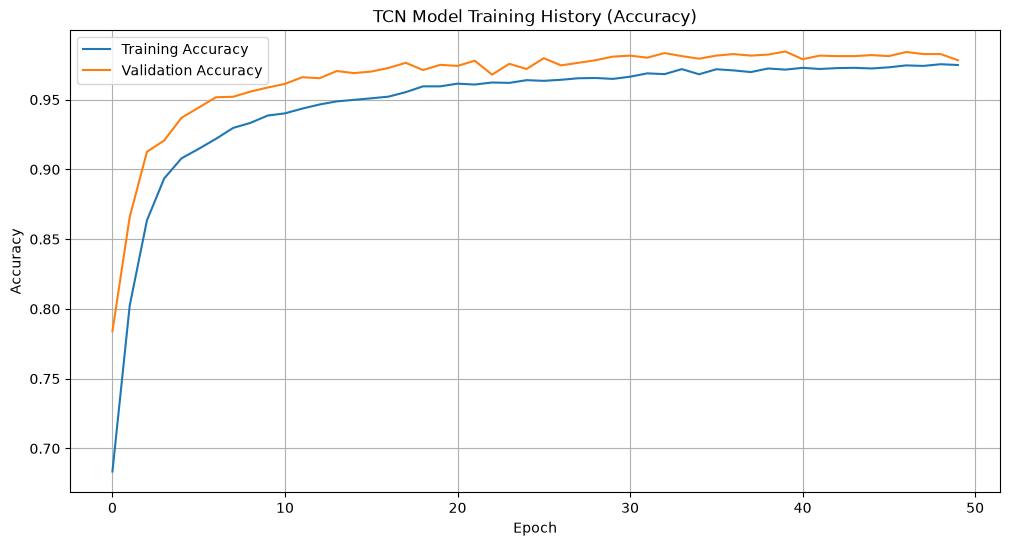

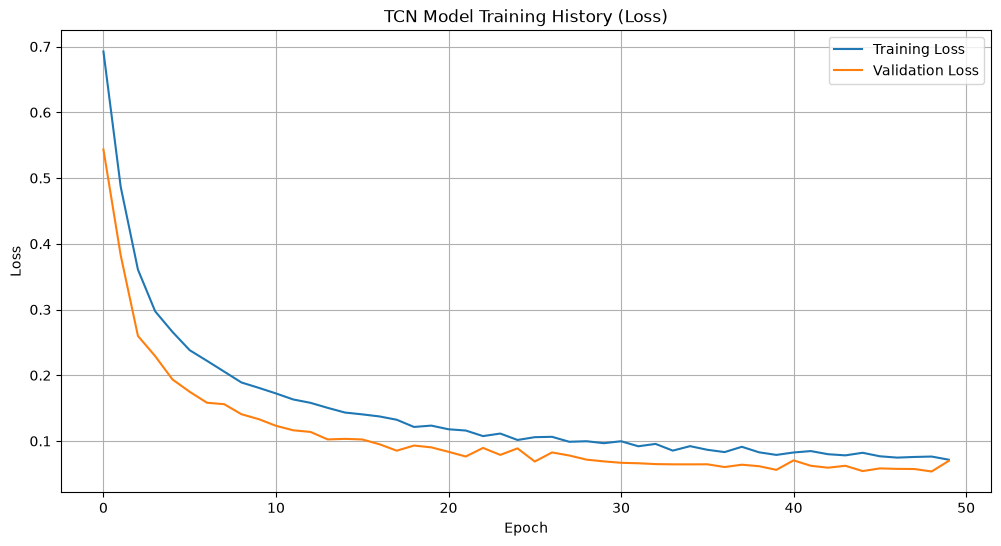

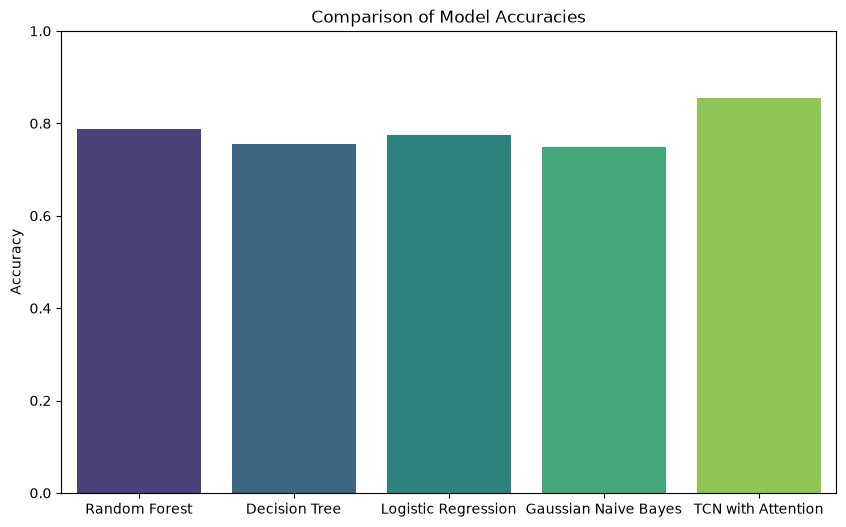

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot TCN training history
plt.figure(figsize=(12, 6))
plt.plot(history_tcn_attention.history['accuracy'], label='Training Accuracy')
plt.plot(history_tcn_attention.history['val_accuracy'], label='Validation Accuracy')
plt.title('TCN Model Training History (Accuracy)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(history_tcn_attention.history['loss'], label='Training Loss')
plt.plot(history_tcn_attention.history['val_loss'], label='Validation Loss')
plt.title('TCN Model Training History (Loss)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Create a bar chart comparing model accuracies (all 5 models)
model_names = ['Random Forest', 'Decision Tree', 'Logistic Regression', 'Gaussian Naive Bayes', 'TCN with Attention']
accuracies = [model.score(X_test, y_test), decision_tree_model.score(X_test, y_test),
              accuracy_lr, accuracy_nb, accuracy_tcn_attention]

plt.figure(figsize=(10, 6))
sns.barplot(x=model_names, y=accuracies, hue=model_names, palette='viridis', legend=False)
plt.title('Comparison of Model Accuracies')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()


## Step 14: Precision, recall and F1 for every model and class

181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
               Model  Class  Precision  Recall  F1-score
       Random Forest  Women     0.7884  0.5003    0.6121
       Random Forest  Child     0.6491  0.9162    0.7599
       Random Forest Normal     0.9994  0.9490    0.9736
       Decision Tree  Women     0.6855  0.5220    0.5927
       Decision Tree  Child     0.6522  0.8433    0.7355
       Decision Tree Normal     0.9565  0.9012    0.9280
 Logistic Regression  Women     0.8039  0.4526    0.5791
 Logistic Regression  Child     0.6378  0.9635    0.7675
 Logistic Regression Normal     0.9834  0.9054    0.9428
Gaussian Naive Bayes  Women     0.7968  0.3577    0.4937
Gaussian Naive Bayes  Child     0.5936  0.9502    0.7307
Gaussian Naive Bayes Normal     0.9978  0.9422    0.9692
  TCN with Attention  Women     0.8841  0.6563    0.7533
  TCN with Attention  Child     0.7506  0.9728    0.8474
  TCN with Attention Normal     0.9781  0.9374    0.9573


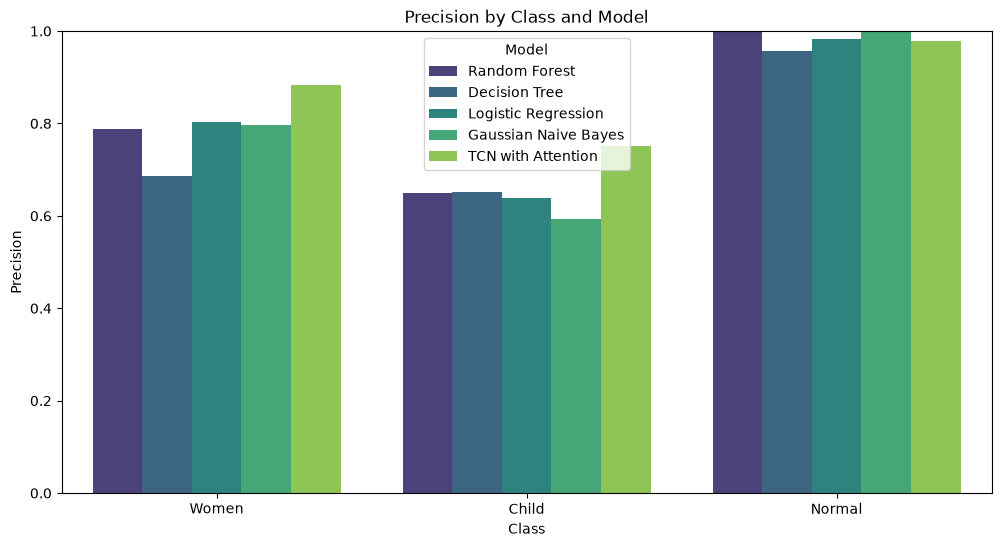

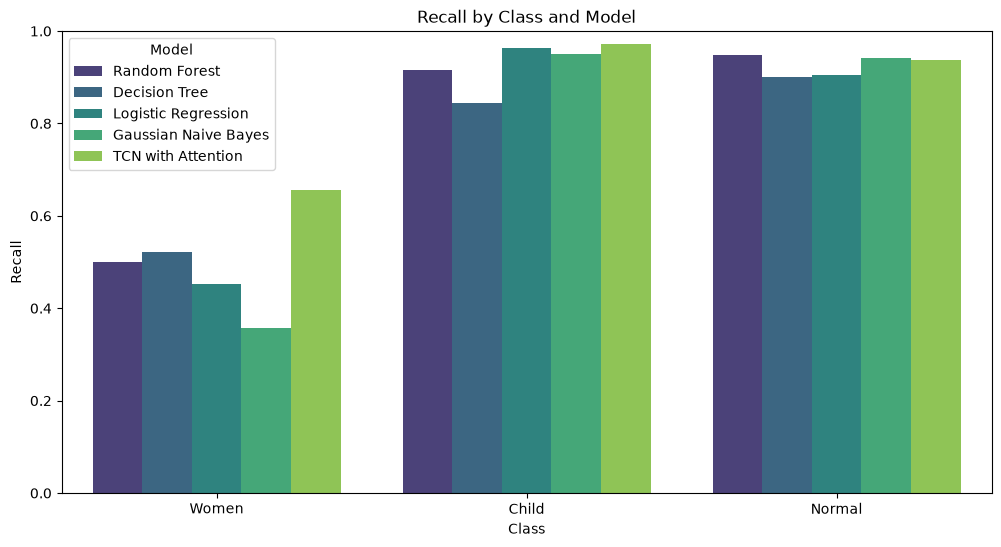

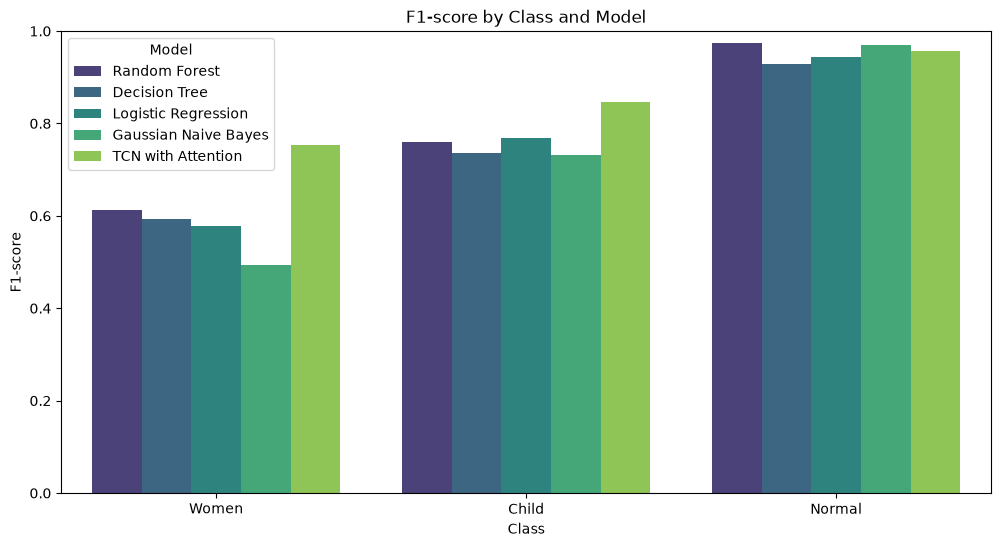

In [18]:
import pandas as pd
from sklearn.metrics import classification_report

# Predictions from each model (TCN predicts numbers, so convert back to names)
y_pred_tcn = label_encoder.inverse_transform(
    tcn_attention_model.predict(X_test_tcn).argmax(axis=1)
)

predictions = {
    "Random Forest": model.predict(X_test),
    "Decision Tree": decision_tree_model.predict(X_test),
    "Logistic Regression": y_pred_lr,
    "Gaussian Naive Bayes": y_pred_nb,
    "TCN with Attention": y_pred_tcn,
}

# Collect one row per model and class
rows = []
for model_name, y_pred_m in predictions.items():
    report = classification_report(y_test, y_pred_m, output_dict=True)
    for class_name in ["Women", "Child", "Normal"]:
        rows.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"],
        })

results_table = pd.DataFrame(rows)
print(results_table.round(4).to_string(index=False))

# Per-class charts for all 5 models
for metric in ["Precision", "Recall", "F1-score"]:
    plt.figure(figsize=(12, 6))
    sns.barplot(data=results_table, x="Class", y=metric, hue="Model", palette="viridis")
    plt.title(f"{metric} by Class and Model")
    plt.ylim(0, 1)
    plt.show()


## Step 15: Final accuracy of all models

In [19]:
print(f"Random Forest Model Accuracy: {model.score(X_test, y_test):.4f}")
print(f"Decision Tree Model Accuracy: {decision_tree_model.score(X_test, y_test):.4f}")
print(f"Logistic Regression Model Accuracy: {accuracy_lr:.4f}")
print(f"Gaussian Naive Bayes Model Accuracy: {accuracy_nb:.4f}")
print(f"TCN with Attention Model Accuracy: {accuracy_tcn_attention:.4f}")


Random Forest Model Accuracy: 0.7881
Decision Tree Model Accuracy: 0.7551
Logistic Regression Model Accuracy: 0.7738
Gaussian Naive Bayes Model Accuracy: 0.7497
TCN with Attention Model Accuracy: 0.8555


## Step 16: AUC scores (one-vs-rest)

In [20]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelBinarizer

print("AUC Scores (One-vs-Rest):")
print("-" * 30)

# Label Binarizer for one-vs-rest AUC calculation
lb = LabelBinarizer()
y_test_binarized = lb.fit_transform(y_test)

# Function to calculate AUC for a given model
def calculate_auc(model, X_test, y_test_binarized, label_binarizer):
    # For scikit-learn models, we can use predict_proba
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test)
    # For Keras models, use predict
    elif hasattr(model, 'predict'):
        # Need to reshape X_test for the TCN model if it's a Keras model
        if isinstance(X_test, pd.DataFrame):
             X_test_reshaped = X_test.values.reshape(X_test.shape[0], X_test.shape[1], 1)
        else:
            X_test_reshaped = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)
        y_score = model.predict(X_test_reshaped)
    else:
        return "Model does not support probability prediction."

    auc_scores = {}
    for i in range(len(label_binarizer.classes_)):
        class_name = label_binarizer.classes_[i]
        try:
            auc = roc_auc_score(y_test_binarized[:, i], y_score[:, i])
            auc_scores[class_name] = auc
        except ValueError as e:
            auc_scores[class_name] = f"Could not calculate AUC: {e}"
    return auc_scores

# Calculate and print AUC for each model
auc_rf = calculate_auc(model, X_test, y_test_binarized, lb)
print("Random Forest:")
for class_name, auc_score in auc_rf.items():
    print(f"  {class_name}: {auc_score:.4f}" if isinstance(auc_score, float) else f"  {class_name}: {auc_score}")
print("-" * 30)

auc_dt = calculate_auc(decision_tree_model, X_test, y_test_binarized, lb)
print("Decision Tree:")
for class_name, auc_score in auc_dt.items():
     print(f"  {class_name}: {auc_score:.4f}" if isinstance(auc_score, float) else f"  {class_name}: {auc_score}")
print("-" * 30)

auc_lr = calculate_auc(log_reg_model, X_test_scaled, y_test_binarized, lb)
print("Logistic Regression:")
for class_name, auc_score in auc_lr.items():
     print(f"  {class_name}: {auc_score:.4f}" if isinstance(auc_score, float) else f"  {class_name}: {auc_score}")
print("-" * 30)

auc_nb = calculate_auc(nb_model, X_test, y_test_binarized, lb)
print("Gaussian Naive Bayes:")
for class_name, auc_score in auc_nb.items():
     print(f"  {class_name}: {auc_score:.4f}" if isinstance(auc_score, float) else f"  {class_name}: {auc_score}")
print("-" * 30)

# For TCN with Attention, use the already reshaped X_test_tcn
auc_tcn_attention = calculate_auc(tcn_attention_model, X_test_tcn, y_test_binarized, lb)
print("TCN with Attention:")
for class_name, auc_score in auc_tcn_attention.items():
     print(f"  {class_name}: {auc_score:.4f}" if isinstance(auc_score, float) else f"  {class_name}: {auc_score}")
print("-" * 30)

AUC Scores (One-vs-Rest):
------------------------------
Random Forest:
  Child: 0.9480
  Normal: 0.9997
  Women: 0.9120
------------------------------
Decision Tree:
  Child: 0.8074
  Normal: 0.9405
  Women: 0.7010
------------------------------
Logistic Regression:
  Child: 0.9142
  Normal: 0.9974
  Women: 0.8505
------------------------------
Gaussian Naive Bayes:
  Child: 0.9007
  Normal: 0.9990
  Women: 0.8690
------------------------------
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
TCN with Attention:
  Child: 0.9714
  Normal: 0.9966
  Women: 0.9362
------------------------------


## Notes
- Training uses the `train` folder and the final scores come from the separate `test` folder.
- For a safety application a missed danger call matters more than a false alarm, so look at **recall** for the Women class.